# Optimizers on a Handwritten-Digit Network

This demo trains the same two-hidden-layer ReLU network on handwritten digits
with momentum SGD, AdaGrad, RMSProp, Adam, and Muon. The task is actual
ten-class prediction; we measure held-out cross-entropy and accuracy after
each epoch. Every run uses the same initial weights, split, and shuffled
minibatch order. Learning rates are declared below and were chosen to make
each method train stably, so **the curves do not establish a universal winner**.

Muon updates only the two hidden weight matrices. AdamW updates its biases and
output head. This notebook needs PyTorch with `torch.optim.Muon` (2.9 or
later). The CSV is fetched automatically when the notebook opens by itself
in Colab.

In [1]:
from pathlib import Path
import urllib.request
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split

SEED = 26512
torch.manual_seed(SEED)
torch.set_num_threads(1)
if not hasattr(torch.optim, 'Muon'):
    raise RuntimeError('This demo needs PyTorch 2.9+ with torch.optim.Muon.')
csv = Path('SklearnDigits.csv')
if not csv.exists():
    url = ('https://raw.githubusercontent.com/ZhuoranYang/sds265-fall26/'
           'main/demos/12-neural-optimization/SklearnDigits.csv')
    urllib.request.urlretrieve(url, csv)
frame = pd.read_csv(csv)
X_all = frame.drop(columns='target').to_numpy(np.float32) / 16.0
y_all = frame['target'].to_numpy(np.int64)
idx_train, idx_valid = train_test_split(
    np.arange(len(y_all)), test_size=0.25, random_state=SEED,
    stratify=y_all
)
X_train = torch.tensor(X_all[idx_train])
y_train = torch.tensor(y_all[idx_train])
X_valid = torch.tensor(X_all[idx_valid])
y_valid = torch.tensor(y_all[idx_valid])
train_data = TensorDataset(X_train, y_train)
print('train:', tuple(X_train.shape), 'validation:', tuple(X_valid.shape))
print('PyTorch:', torch.__version__)

train: (1347, 64) validation: (450, 64)
PyTorch: 2.10.0


## Same model and data order for every run

The network maps 64 pixel values through hidden widths 128 and 64 to ten
class logits. The hidden ReLU layers use He initialization, with weight
variance $2/\mathrm{fan\_in}$; the linear output head uses Xavier
initialization, with variance $2/(\mathrm{fan\_in}+\mathrm{fan\_out})$.
We save this initial state and restore it before each run. Recreating the
data loader with the same seed gives every method the same minibatches in
the same order. All methods use zero weight decay here to isolate their
update rules.

In [2]:
def make_model():
    model = nn.Sequential(
        nn.Linear(64, 128), nn.ReLU(),
        nn.Linear(128, 64), nn.ReLU(),
        nn.Linear(64, 10)
    )
    for layer in (model[0], model[2]):
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
            nn.init.zeros_(layer.bias)
    nn.init.xavier_normal_(model[4].weight)
    nn.init.zeros_(model[4].bias)
    return model

torch.manual_seed(SEED)
initial_state = {key: value.clone() for key, value in make_model().state_dict().items()}

RATES = {
    'SGD + momentum': 0.10,
    'AdaGrad': 0.045,
    'RMSProp': 0.002,
    'Adam': 0.002,
    'Muon + AdamW': 0.020,
}
EPOCHS = 25
BATCH_SIZE = 128

def make_optimizers(name, model):
    lr = RATES[name]
    if name == 'SGD + momentum':
        return [torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)]
    if name == 'AdaGrad':
        return [torch.optim.Adagrad(model.parameters(), lr=lr)]
    if name == 'RMSProp':
        return [torch.optim.RMSprop(model.parameters(), lr=lr, alpha=0.99)]
    if name == 'Adam':
        return [torch.optim.Adam(model.parameters(), lr=lr)]
    hidden = [model[0].weight, model[2].weight]
    hidden_ids = {id(p) for p in hidden}
    other = [p for p in model.parameters() if id(p) not in hidden_ids]
    muon = torch.optim.Muon(hidden, lr=lr, momentum=0.95, weight_decay=0.0)
    adamw = torch.optim.AdamW(other, lr=0.002, weight_decay=0.0)
    return [muon, adamw]

def evaluate(model):
    model.eval()
    with torch.no_grad():
        logits = model(X_valid)
        loss = float(nn.functional.cross_entropy(logits, y_valid))
        accuracy = float((logits.argmax(1) == y_valid).float().mean())
    return loss, accuracy

def train_one(name):
    model = make_model()
    model.load_state_dict(initial_state)
    optimizers = make_optimizers(name, model)
    loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    rows = []
    steps = 0
    start = time.perf_counter()
    for epoch in range(1, EPOCHS+1):
        model.train()
        for xb, yb in loader:
            for opt in optimizers:
                opt.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(xb), yb)
            loss.backward()
            for opt in optimizers:
                opt.step()
            steps += 1
        valid_loss, valid_accuracy = evaluate(model)
        rows.append({'method': name, 'epoch': epoch, 'optimizer steps': steps,
                     'validation loss': valid_loss,
                     'validation accuracy': valid_accuracy,
                     'elapsed seconds': time.perf_counter()-start})
    return pd.DataFrame(rows)

print('model parameters:', sum(p.numel() for p in make_model().parameters()))
print('optimizer learning rates:', RATES)
print('Muon uses 0.002 for its auxiliary AdamW parameters.')

model parameters: 17226
optimizer learning rates: {'SGD + momentum': 0.1, 'AdaGrad': 0.045, 'RMSProp': 0.002, 'Adam': 0.002, 'Muon + AdamW': 0.02}
Muon uses 0.002 for its auxiliary AdamW parameters.


## Train and compare

The first plot uses optimizer steps on the horizontal axis and held-out
cross-entropy on the vertical axis. The second shows held-out classification
accuracy. The table reports the last epoch and the best validation accuracy
reached within this fixed budget. Wall-clock times are shown separately:
Muon's matrix orthogonalization costs work that step counts do not capture.
Do not choose a method from a single run; learning-rate tuning and repeated
seeds would be needed for a performance claim.

,final_loss,final_accuracy,best_accuracy,seconds
method,,,,
SGD + momentum,0.054,0.980,0.984,0.199
AdaGrad,0.058,0.976,0.978,0.183
RMSProp,0.048,0.980,0.982,0.185
Adam,0.070,0.976,0.980,0.202
Muon + AdamW,0.038,0.984,0.991,1.156


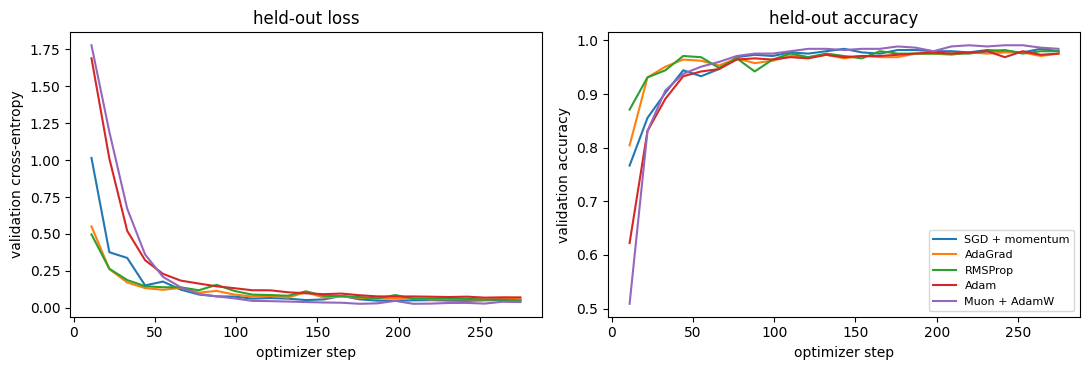

In [3]:
histories = [train_one(name) for name in RATES]
history = pd.concat(histories, ignore_index=True)
summary = history.groupby('method', sort=False).agg(
    final_loss=('validation loss', 'last'),
    final_accuracy=('validation accuracy', 'last'),
    best_accuracy=('validation accuracy', 'max'),
    seconds=('elapsed seconds', 'last'),
).round(3)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, group in history.groupby('method', sort=False):
    axes[0].plot(group['optimizer steps'], group['validation loss'], label=name)
    axes[1].plot(group['optimizer steps'], group['validation accuracy'], label=name)
axes[0].set(xlabel='optimizer step', ylabel='validation cross-entropy',
            title='held-out loss')
axes[1].set(xlabel='optimizer step', ylabel='validation accuracy',
            title='held-out accuracy')
axes[1].legend(fontsize=8, loc='lower right')
fig.tight_layout()
plt.show()

## What Muon changes

The first four methods rescale or smooth coordinates of a gradient. Muon
instead treats each hidden weight as a matrix: it builds a momentum update
and approximately orthogonalizes that matrix with Newton–Schulz iterations.
Bias vectors and the final classification head are handled by AdamW. This
comparison shows what those choices do on one small network; it does not
imply that Muon must outperform the other methods on every task.

Reference: [PyTorch Muon documentation](https://docs.pytorch.org/docs/stable/generated/torch.optim.Muon.html).